# The Economics of Luxury | Financial Intelligence
**Hermès · LVMH · Kering | FY2023–FY2025 (coverage varies)**

An investment-committee-style operating performance study. Data is sourced from company filings; assumptions are clearly separated from observed results. **Not investment advice.**

## Executive questions
1. Which group earns the highest recurring operating margin?
2. How much of the 2024–2025 operating-profit change reflects revenue contraction versus margin compression?
3. Which LVMH segments account for profit concentration?
4. How sensitive is FY2025 profit to changes in revenue and operating margin?

**Coverage caveat:** LVMH has 2023–2025; Hermès and Kering have 2024–2025. Kering 2024 uses the FY2025 restated continuing-operations comparative.

In [1]:
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import sqlite3
BASE = Path(".")
financials = pd.read_csv(BASE / "data/luxury_company_financials.csv")
segments = pd.read_csv(BASE / "data/lvmh_segments.csv")
financials.sort_values(["company", "year"])

,company,year,revenue_eur_m,recurring_operating_income_eur_m,gross_profit_eur_m,net_income_eur_m,basis_note,source_url,recurring_operating_margin_pct,gross_margin_pct,reported_revenue_yoy_pct
0,Hermes,2024,15170,6150,10660,NaN,2025 comparative,https://assets-finance.hermes.com/s3fs-public/...,40.540541,70.270270,NaN
1,Hermes,2025,16002,6569,11379,NaN,2025 full year,https://assets-finance.hermes.com/s3fs-public/...,41.051119,71.109861,5.484509
2,Kering,2024,16874,2440,12394,1133.0,2025 comparative; continuing operations restated,https://www.kering.com/api/download-file/?path...,14.460116,73.450279,NaN
3,Kering,2025,14675,1631,10660,72.0,2025 full year; continuing operations excludin...,https://www.kering.com/api/download-file/?path...,11.114140,72.640545,-13.031883
4,LVMH,2023,86153,22802,59277,15952.0,key figures,https://www.lvmh.com/investors/key-figures,26.466867,68.804336,NaN
5,LVMH,2024,84683,19571,56765,12958.0,key figures,https://www.lvmh.com/investors/key-figures,23.110896,67.032344,-1.706267
6,LVMH,2025,80807,17755,53528,11222.0,key figures,https://www.lvmh.com/investors/key-figures,21.972106,66.241786,-4.577070


## 1 · Data validation and coverage
No missing revenues, duplicate company-years or invalid operating margins are accepted. Missing net income is left missing rather than fabricated.

In [2]:
assert not financials.duplicated(["company", "year"]).any()
assert financials["revenue_eur_m"].notna().all()
assert (financials["revenue_eur_m"] > 0).all()
financials["computed_margin_pct"] = 100 * financials["recurring_operating_income_eur_m"] / financials["revenue_eur_m"]
assert np.allclose(financials["computed_margin_pct"], financials["recurring_operating_margin_pct"])
print("Company-year observations:", len(financials))
print(financials.groupby("company")["year"].agg(["min", "max", "count"]))

Company-year observations: 7
          min   max  count
company                   
Hermes   2024  2025      2
Kering   2024  2025      2
LVMH     2023  2025      3


## 2 · Profitability and scale

,company,revenue_eur_m,recurring_operating_income_eur_m,computed_margin_pct
1,Hermes,16002,6569,41.05
6,LVMH,80807,17755,21.97
3,Kering,14675,1631,11.11


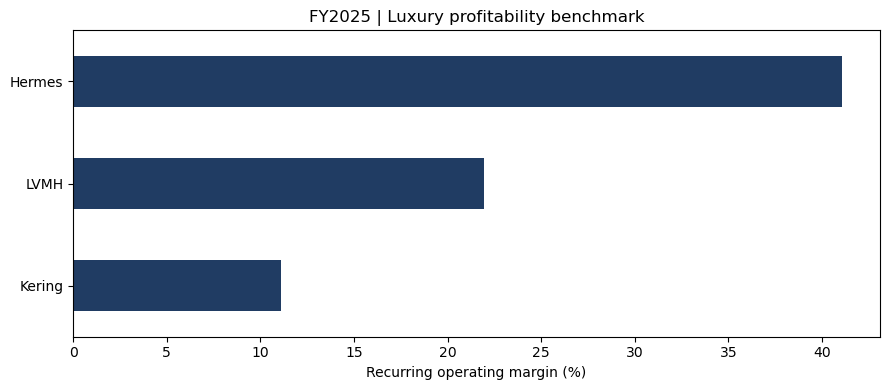

In [3]:
latest = financials.query("year == 2025").sort_values("computed_margin_pct", ascending=False)
display(latest[["company", "revenue_eur_m", "recurring_operating_income_eur_m", "computed_margin_pct"]].round(2))
ax = latest.sort_values("computed_margin_pct").plot.barh(x="company",y="computed_margin_pct",legend=False,figsize=(9,4),color="#203c63")
ax.set(xlabel="Recurring operating margin (%)",ylabel="",title="FY2025 | Luxury profitability benchmark");plt.tight_layout();plt.show()

## 3 · Operating profit bridge: scale versus margin
Exact arithmetic identity: **Δ operating profit = (R₁−R₀) × m₀ + R₁ × (m₁−m₀)**, where m = operating profit / revenue. This is an **accounting decomposition**, not causal attribution to pricing, volume or managerial decisions.

,company,revenue_effect_eur_m,margin_effect_eur_m,profit_change_eur_m
0,Hermes,337.3,81.7,419
1,Kering,-318.0,-491.0,-809
2,LVMH,-895.8,-920.2,-1816


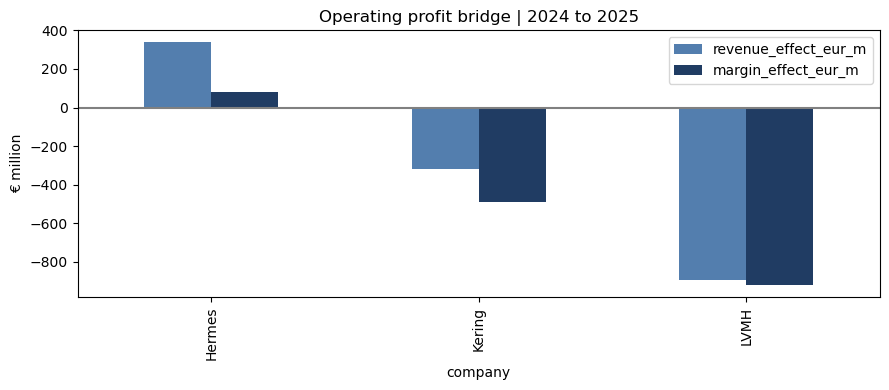

In [4]:
bridges=[]
for company, group in financials.groupby("company"):
    g=group.set_index("year")
    if {2024,2025}.issubset(g.index):
        a,b=g.loc[2024],g.loc[2025]
        m0=a.recurring_operating_income_eur_m/a.revenue_eur_m
        m1=b.recurring_operating_income_eur_m/b.revenue_eur_m
        scale=(b.revenue_eur_m-a.revenue_eur_m)*m0
        margin=b.revenue_eur_m*(m1-m0)
        actual=b.recurring_operating_income_eur_m-a.recurring_operating_income_eur_m
        assert abs(scale+margin-actual)<1e-6
        bridges.append({"company":company,"revenue_effect_eur_m":scale,"margin_effect_eur_m":margin,"profit_change_eur_m":actual})
bridge=pd.DataFrame(bridges)
display(bridge.round(1))
bridge.set_index("company")[["revenue_effect_eur_m","margin_effect_eur_m"]].plot.bar(figsize=(9,4),color=["#537eae","#203c63"]);plt.axhline(0,color="gray");plt.title("Operating profit bridge | 2024 to 2025");plt.ylabel("€ million");plt.tight_layout();plt.show()

## 4 · LVMH segment economics
LVMH segments differ materially in operating margin and absolute profit contribution. Segment totals do not equal consolidated profit until corporate costs and eliminations are included.

,segment,revenue_eur_m,recurring_operating_income_eur_m,margin_pct_check
5,Fashion & Leather Goods,37770,13209,35.0
14,Selective Retailing,18348,1780,9.7
11,Watches & Jewelry,10486,1514,14.4
2,Wines & Spirits,5358,1016,19.0
8,Perfumes & Cosmetics,8174,727,8.9


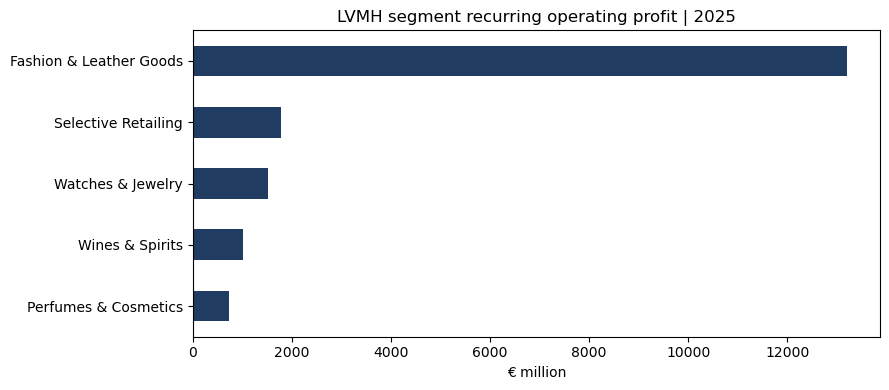

In [5]:
s=segments.query("year == 2025").copy()
s["margin_pct_check"]=100*s.recurring_operating_income_eur_m/s.revenue_eur_m
display(s[["segment","revenue_eur_m","recurring_operating_income_eur_m","margin_pct_check"]].sort_values("recurring_operating_income_eur_m",ascending=False).round(1))
ax=s.sort_values("recurring_operating_income_eur_m").plot.barh(x="segment",y="recurring_operating_income_eur_m",legend=False,figsize=(9,4),color="#203c63")
ax.set(xlabel="€ million",ylabel="",title="LVMH segment recurring operating profit | 2025");plt.tight_layout();plt.show()

## 5 · Forward-looking scenario sensitivity (illustrative)
Change FY2025 revenue by −10% to +10% and operating margin by −3 to +3 percentage points. These are **user-defined assumptions, not forecasts**. They hold all other factors constant.

In [6]:
scenarios=[]
for _,r in latest.iterrows():
    base_margin=r.computed_margin_pct
    for growth in [-.10,-.05,0,.05,.10]:
        for margin_pp in [-3,0,3]:
            rev=r.revenue_eur_m*(1+growth)
            op=rev*(base_margin+margin_pp)/100
            scenarios.append({"company":r.company,"revenue_growth_pct":growth*100,"margin_change_pp":margin_pp,"scenario_profit_eur_m":op,"change_vs_base_eur_m":op-r.recurring_operating_income_eur_m})
scenario=pd.DataFrame(scenarios)
display(scenario.query("company == 'Hermes'").pivot(index="margin_change_pp",columns="revenue_growth_pct",values="change_vs_base_eur_m").round(0))

revenue_growth_pct,-10.0,-5.0,0.0,5.0,10.0
margin_change_pp,,,,,
-3,-1089.0,-785.0,-480.0,-176.0,129.0
0,-657.0,-328.0,0.0,328.0,657.0
3,-225.0,128.0,480.0,833.0,1185.0


## 6 · SQL validation and analytical reuse

In [7]:
with sqlite3.connect(BASE / "data/luxury_financial_intelligence.sqlite") as con:
    result=pd.read_sql_query("SELECT company, year, revenue_eur_m, ROUND(100.0*recurring_operating_income_eur_m/revenue_eur_m,2) AS operating_margin_pct FROM company_financials WHERE year=2025 ORDER BY operating_margin_pct DESC",con)
display(result)

,company,year,revenue_eur_m,operating_margin_pct
0,Hermes,2025,16002,41.05
1,LVMH,2025,80807,21.97
2,Kering,2025,14675,11.11


## Interpretation and limits
- Hermès has the highest 2025 recurring operating margin, not the highest absolute revenue.
- LVMH is the largest group by revenue; its Fashion & Leather Goods division is central to group profit.
- Kering is in a different financial position, with substantial margin compression; **its 2024 comparator is restated**.
- Company-level revenue and profit do not reveal a clean **price-versus-volume** split. Do not label the bridge “pricing effect.”
- These are a handful of groups, not a statistically representative sample; regression and significance tests would be misleading here.
- Scenario outputs are conditional illustrations, not predictions.

See `sources_and_methodology.md` for exact reporting definitions and source links.